In [1]:
#Load and inspect data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ecommerce_logistics.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.head())


Dataset shape: (30, 15)

Column names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Product_Category', 'Order_Value', 'Shipping_Cost', 'Warehouse', 'Delivery_Partner', 'Delivery_Days', 'Expected_Days', 'Order_Status', 'Customer_Rating', 'Return_Flag', 'Inventory_Level', 'Reorder_Level']

Missing values:
Order_ID            0
Order_Date          0
Customer_ID         0
Product_Category    0
Order_Value         0
Shipping_Cost       0
Warehouse           0
Delivery_Partner    0
Delivery_Days       0
Expected_Days       0
Order_Status        0
Customer_Rating     0
Return_Flag         0
Inventory_Level     0
Reorder_Level       0
dtype: int64

Duplicate rows: 0


,Order_ID,Order_Date,Customer_ID,Product_Category,Order_Value,Shipping_Cost,Warehouse,Delivery_Partner,Delivery_Days,Expected_Days,Order_Status,Customer_Rating,Return_Flag,Inventory_Level,Reorder_Level
0,ORD1001,2026-01-02,CUST001,Electronics,45000,650,Bangalore,Delivery,3,4,Delivered,5,No,25,20
1,ORD1002,2026-01-03,CUST002,Fashion,2500,180,Mumbai,BlueDart,2,3,Delivered,4,No,10,15
2,ORD1003,2026-01-04,CUST003,Home & Kitchen,7800,320,Delhi,Ecom Express,5,4,Delivered,3,No,30,20
3,ORD1004,2026-01-05,CUST004,Beauty,1500,120,Bangalore,Delivery,2,3,Delivered,5,No,8,10
4,ORD1005,2026-01-06,CUST005,Electronics,32000,550,Hyderabad,BlueDart,4,4,Delivered,4,No,50,25


In [2]:
# Convert KPI columns to numeric
for col in [
    "Shipping_Cost",
    "Delivery_Days",
    "Expected_Days",
    "Inventory_Level"
]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Average delivery days
avg_delivery_days = df["Delivery_Days"].mean()

# Average shipping cost
avg_shipping_cost = df["Shipping_Cost"].mean()

# On-time delivery rate
valid_delivery = df.dropna(
    subset=["Delivery_Days", "Expected_Days"]
)

on_time_rate = (
    valid_delivery["Delivery_Days"]
    .le(valid_delivery["Expected_Days"])
    .mean() * 100
    if not valid_delivery.empty else np.nan
)

# Stockout rate (row-based definition)
valid_inventory = df["Inventory_Level"].dropna()

stockout_rate = (
    valid_inventory.eq(0).mean() * 100
    if not valid_inventory.empty else np.nan
)

print(f"Average Delivery Days: {avg_delivery_days:.2f}")
print(f"Average Shipping Cost: {avg_shipping_cost:.2f}")
print(f"On-Time Delivery Rate: {on_time_rate:.2f}%")
print(f"Stockout Rate: {stockout_rate:.2f}%")

Average Delivery Days: 3.57
Average Shipping Cost: 306.83
On-Time Delivery Rate: 70.00%
Stockout Rate: 0.00%


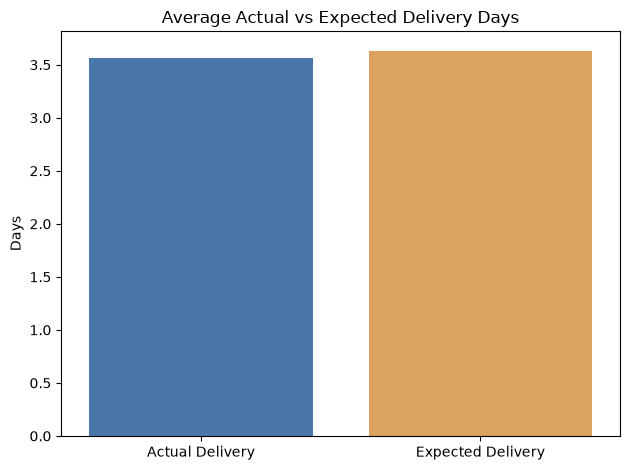

In [3]:
# Actual Vs Expected Delivery
delivery_comparison = pd.DataFrame({
    "Delivery Type": ["Actual Delivery", "Expected Delivery"],
    "Days": [
        df["Delivery_Days"].mean(),
        df["Expected_Days"].mean()
    ]
})

sns.barplot(
    data=delivery_comparison,
    x="Delivery Type",
    y="Days",
    hue="Delivery Type",
    palette=["#3976B9", "#F0A44B"],
    legend=False
)

plt.title("Average Actual vs Expected Delivery Days")
plt.ylabel("Days")
plt.xlabel("")
plt.tight_layout()
plt.show()

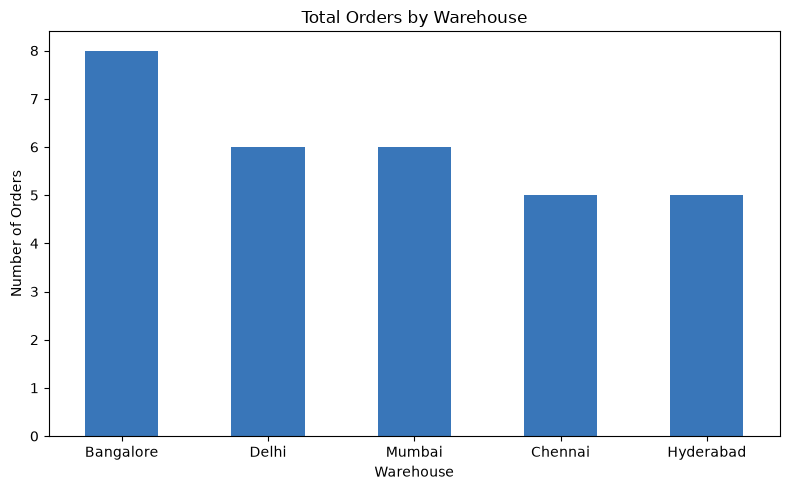

In [4]:
#Order By Warehouse
warehouse_orders = (
    df.groupby("Warehouse")["Order_ID"]
      .nunique()
      .sort_values(ascending=False)
)

warehouse_orders.plot(
    kind="bar",
    color="#3976B9",
    figsize=(8, 5)
)

plt.title("Total Orders by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Total_Orders,On_Time_Rate,Avg_Shipping_Cost
Delivery_Partner,,,
BlueDart,10,90.0,306.5
Delivery,10,80.0,240.0
Ecom Express,10,40.0,374.0


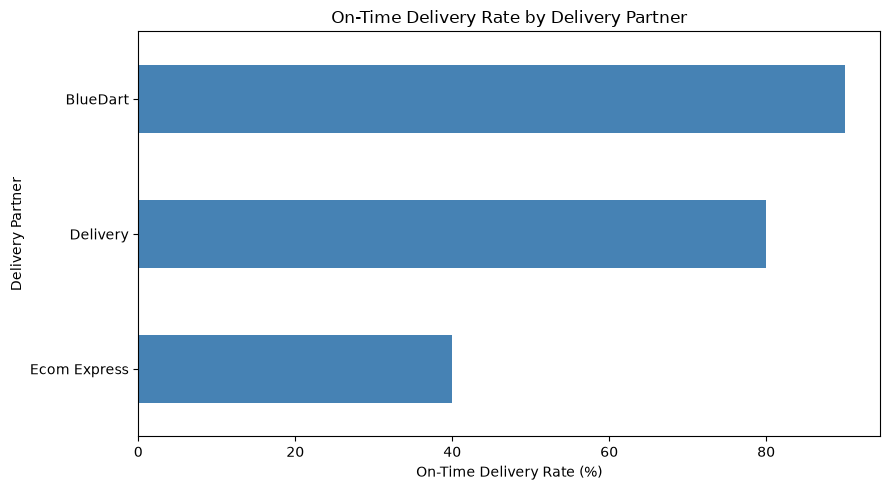

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load dataset
df = pd.read_csv("ecommerce_logistics.csv")

# 2. Clean column names
df.columns = df.columns.str.strip()

# 3. Convert required columns to numeric
for col in ["Delivery_Days", "Expected_Days", "Shipping_Cost"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 4. Validate required columns
required = [
    "Order_ID", "Delivery_Partner",
    "Delivery_Days", "Expected_Days", "Shipping_Cost"
]

missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# 5. Keep rows with valid delivery information
valid_df = df.dropna(
    subset=[
        "Order_ID", "Delivery_Partner",
        "Delivery_Days", "Expected_Days"
    ]
).copy()

# 6. Calculate on-time status
valid_df["On_Time"] = (
    valid_df["Delivery_Days"] <= valid_df["Expected_Days"]
)

# 7. Summarize partner performance
partner_performance = (
    valid_df.groupby("Delivery_Partner")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        On_Time_Rate=("On_Time", "mean"),
        Avg_Shipping_Cost=("Shipping_Cost", "mean")
    )
)

# 8. Convert rate to percentage
partner_performance["On_Time_Rate"] *= 100

# 9. Display results
display(partner_performance.round(2))

# 10. Plot delivery partner performance
partner_performance["On_Time_Rate"].sort_values().plot(
    kind="barh",
    color="steelblue",
    figsize=(9, 5)
)

plt.title("On-Time Delivery Rate by Delivery Partner")
plt.xlabel("On-Time Delivery Rate (%)")
plt.ylabel("Delivery Partner")
plt.tight_layout()
plt.show()

In [26]:
%pip install --user pandas matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
%pip install pandas matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
#Load Dataset:

import pandas as pd
df = pd.read_csv("ecommerce_logistics.csv")
print(df.head())


  Order_ID  Order_Date Customer_ID Product_Category  Order_Value  \
0  ORD1001  2026-01-02     CUST001      Electronics        45000   
1  ORD1002  2026-01-03     CUST002          Fashion         2500   
2  ORD1003  2026-01-04     CUST003   Home & Kitchen         7800   
3  ORD1004  2026-01-05     CUST004           Beauty         1500   
4  ORD1005  2026-01-06     CUST005      Electronics        32000   

   Shipping_Cost  Warehouse Delivery_Partner  Delivery_Days  Expected_Days  \
0            650  Bangalore        Delhivery              3              4   
1            180     Mumbai         BlueDart              2              3   
2            320      Delhi     Ecom Express              5              4   
3            120  Bangalore        Delhivery              2              3   
4            550  Hyderabad         BlueDart              4              4   

  Order_Status  Customer_Rating Return_Flag  Inventory_Level  Reorder_Level  
0    Delivered                5          No 

In [29]:
#Dataset Information:
import pandas as pd
print(df.info())
print(df.describe())


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Order_ID          30 non-null     str  
 1   Order_Date        30 non-null     str  
 2   Customer_ID       30 non-null     str  
 3   Product_Category  30 non-null     str  
 4   Order_Value       30 non-null     int64
 5   Shipping_Cost     30 non-null     int64
 6   Warehouse         30 non-null     str  
 7   Delivery_Partner  30 non-null     str  
 8   Delivery_Days     30 non-null     int64
 9   Expected_Days     30 non-null     int64
 10  Order_Status      30 non-null     str  
 11  Customer_Rating   30 non-null     int64
 12  Return_Flag       30 non-null     str  
 13  Inventory_Level   30 non-null     int64
 14  Reorder_Level     30 non-null     int64
dtypes: int64(7), str(8)
memory usage: 3.6 KB
None
        Order_Value  Shipping_Cost  Delivery_Days  Expected_Days  \
count     30.000000     

In [30]:
#Average Delivery Time:

import pandas as pd
average_delivery_time = df["Delivery_Days"].mean()
print("Average Delivery Time:", average_delivery_time)


Average Delivery Time: 3.566666666666667


In [31]:
#Average Shipping Cost:
import pandas as pd
average_shipping_cost = df["Shipping_Cost"].mean()
print("Average Shipping Cost:", average_shipping_cost)


Average Shipping Cost: 306.8333333333333


In [32]:
#Order Fulfilment Rate:
import pandas as pd

total_orders = len(df)

fulfilled_orders = len(
    df[df["Order_Status"] == "Delivered"]
)

fulfilment_rate = (
    fulfilled_orders / total_orders
) * 100

print("Order Fulfilment Rate:", fulfilment_rate)


Order Fulfilment Rate: 100.0


In [33]:
#Stockout Rate
import pandas as pd
stockout_events = len(
    df[df["Inventory_Level"] <= df["Reorder_Level"]]
)

stockout_rate = (
    stockout_events / len(df)
) * 100

print("Stockout Rate:", stockout_rate)


Stockout Rate: 63.33333333333333
